# 05. Risk grades by dong: outflow probability × expected population decrease (report 3.3)
- 04번에서 저장한 최종 모델(model/final_rf_pipeline.joblib)을 joblib으로 불러와 사용 (노트북 방식)
- 예상 인구 감소 = 유출 확률 × 전월 인구 × 그 행정동이 유출된 달의 평균 감소율
  (예시 보고서의 "취소 확률 × 금액 = 예상 손실"과 같은 구조)
- 등급 기준(LOW/MEDIUM/HIGH)은 학습 구간 예측값의 분위수로 정하고, 테스트 구간에서 실제와 비교해 검증
- 기준 분위수는 [CONFIG] 셀의 GRADE_QUANTILES만 고치면 됨
사전설치 : pip install pandas scikit-learn matplotlib joblib

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 노트북에는 __file__이 없으므로 실행 위치(code 폴더 또는 ML 폴더)로 기준 폴더를 정함
BASE_DIR = (Path.cwd().parent if Path.cwd().name == "code" else Path.cwd())
DATA_DIR = BASE_DIR / "데이터_csv"
MODEL_DIR = BASE_DIR / "model"
RESULT_PATH = DATA_DIR / "results_risk_grades.csv"
SUMMARY_PATH = DATA_DIR / "results_risk_grade_summary.csv"

# 폰트지정 (그래프에 행정동 한글 이름이 들어가므로 필요)
plt.rcParams["font.family"] = "Malgun Gothic"
# 마이너스 부호 깨짐 지정
plt.rcParams["axes.unicode_minus"] = False

In [2]:
# [CONFIG]
TARGET = "outflow"
TRAIN_END = "2025-09"
GRADE_QUANTILES = (0.5, 0.8)      # 학습 구간 예상 감소의 50% 미만 LOW, 50~80% MEDIUM, 80% 이상 HIGH
GRADES = ["LOW", "MEDIUM", "HIGH"]
GRADE_COLORS = {"LOW": "tab:green", "MEDIUM": "tab:orange", "HIGH": "tab:red"}

In [3]:
# Load final model and data
pipeline = joblib.load(MODEL_DIR / "final_rf_pipeline.joblib")
meta = joblib.load(MODEL_DIR / "features_meta.joblib")
FEATURES = meta["cat_features"] + meta["num_features"]

df = pd.read_csv(DATA_DIR / "영통구_행정동별_월별_학습데이터셋.csv")
df = df.dropna(subset=FEATURES).reset_index(drop=True)
train = df[df["ym"] <= TRAIN_END].copy()
test = df[df["ym"] > TRAIN_END].copy()

# predict_proba의 두 번째 열 = 유출(1)일 확률
train["outflow_prob"] = pipeline.predict_proba(train[FEATURES])[:, 1]
test["outflow_prob"] = pipeline.predict_proba(test[FEATURES])[:, 1]

In [4]:
# Expected population decrease
# 행정동별 "유출된 달의 평균 감소율"은 학습 구간에서만 계산 (테스트 정보가 섞이지 않도록)
# pop_chg는 목표 계산용 컬럼이라 모델 입력에는 쓰지 않고, 여기서 감소 규모를 정할 때만 사용
train["chg_rate"] = train["pop_chg"] / train["population_lag1"]
outflow_rate = (train[train[TARGET] == 1].groupby("dong")["chg_rate"].mean().abs()
                .rename("avg_outflow_rate"))
print("Average decrease rate in outflow months (train, %):")
print((outflow_rate * 100).round(3).sort_values(ascending=False).to_string())

for d in (train, test):
    d["avg_outflow_rate"] = d["dong"].map(outflow_rate)
    d["expected_decrease"] = d["outflow_prob"] * d["population_lag1"] * d["avg_outflow_rate"]   # 단위: 명

Average decrease rate in outflow months (train, %):
dong
매탄1동    0.561
망포1동    0.238
매탄4동    0.206
영통2동    0.185
원천동     0.174
영통1동    0.152
매탄2동    0.125
망포2동    0.113
영통3동    0.102
광교1동    0.092
광교2동    0.087
매탄3동    0.087


In [5]:
# Grade thresholds from train, applied to test
q_low, q_high = train["expected_decrease"].quantile(GRADE_QUANTILES)
print(f"\nGrade thresholds (expected decrease, persons): MEDIUM >= {q_low:.1f}, HIGH >= {q_high:.1f}")


def to_grade(x):
    return pd.cut(x, bins=[-np.inf, q_low, q_high, np.inf], labels=GRADES, right=False)


train["risk_grade"] = to_grade(train["expected_decrease"])
test["risk_grade"] = to_grade(test["expected_decrease"])


Grade thresholds (expected decrease, persons): MEDIUM >= 24.0, HIGH >= 34.3


In [6]:
# Result 1: grade validation on test (report 3.3)
# 등급이 의미 있으려면 HIGH로 갈수록 실제 유출 비율과 실제 감소 인원이 커져야 함
summary = test.groupby("risk_grade", observed=False).agg(
    rows=("dong", "size"),
    mean_outflow_prob=("outflow_prob", "mean"),
    actual_outflow_ratio=(TARGET, "mean"),
    mean_expected_decrease=("expected_decrease", "mean"),
    mean_actual_pop_chg=("pop_chg", "mean"),
    total_actual_pop_chg=("pop_chg", "sum"),
).reset_index()
print("\nRisk grade validation (test 2025.10 ~ 2026.09):")
print(summary.round(3).to_string(index=False))

# 행정동별로 테스트 12개월 중 각 등급이 몇 번 나왔는지
print("\nGrade count by dong (test):")
print(pd.crosstab(test["dong"], test["risk_grade"]).reindex(columns=GRADES, fill_value=0).to_string())


Risk grade validation (test 2025.10 ~ 2026.09):
risk_grade  rows  mean_outflow_prob  actual_outflow_ratio  mean_expected_decrease  mean_actual_pop_chg  total_actual_pop_chg
       LOW    74              0.537                 0.473                  17.162                3.811                   282
    MEDIUM    41              0.624                 0.634                  29.863              -26.049                 -1068
      HIGH    29              0.631                 0.724                  45.415              -22.759                  -660

Grade count by dong (test):
risk_grade  LOW  MEDIUM  HIGH
dong                         
광교1동          2       9     1
광교2동         12       0     0
망포1동          3       5     4
망포2동         12       0     0
매탄1동          0       0    12
매탄2동         12       0     0
매탄3동         12       0     0
매탄4동          0      12     0
영통1동          3       9     0
영통2동          6       6     0
영통3동         12       0     0
원천동           0       0    12


In [7]:
# Result 2: latest month ranking (report 3.3)
latest_month = test["ym"].max()
latest = (test[test["ym"] == latest_month]
          .sort_values("expected_decrease", ascending=False)
          [["ym", "dong", "outflow_prob", "population_lag1", "expected_decrease", "risk_grade", "pop_chg", TARGET]])
print(f"\nRisk ranking for {latest_month}:")
print(latest.round(3).to_string(index=False))


Risk ranking for 2026-09:
     ym dong  outflow_prob  population_lag1  expected_decrease risk_grade  pop_chg  outflow
2026-09  원천동         0.636          47698.0             52.886       HIGH      517        0
2026-09 매탄1동         0.733          11187.0             45.976       HIGH      -18        1
2026-09 망포1동         0.511          31481.0             38.286       HIGH      -13        1
2026-09 광교1동         0.674          54302.0             33.721     MEDIUM      106        0
2026-09 영통2동         0.660          25412.0             31.020     MEDIUM     -562        1
2026-09 매탄4동         0.637          19735.0             25.908     MEDIUM        2        0
2026-09 영통1동         0.450          32686.0             22.327        LOW      -17        1
2026-09 매탄3동         0.678          34868.0             20.519        LOW      -51        1
2026-09 영통3동         0.509          32755.0             16.950        LOW       11        0
2026-09 광교2동         0.605          28521.0          

In [8]:
# Save results
cols = ["ym", "dong", "outflow_prob", "population_lag1", "avg_outflow_rate", "expected_decrease",
        "risk_grade", "pop_chg", TARGET]
test[cols].round(4).to_csv(RESULT_PATH, index=False, encoding="utf-8-sig")
summary.round(4).to_csv(SUMMARY_PATH, index=False, encoding="utf-8-sig")
print("Saved:", RESULT_PATH)
print("Saved:", SUMMARY_PATH)

Saved: C:\Users\human-13\Desktop\ML\데이터_csv\results_risk_grades.csv
Saved: C:\Users\human-13\Desktop\ML\데이터_csv\results_risk_grade_summary.csv


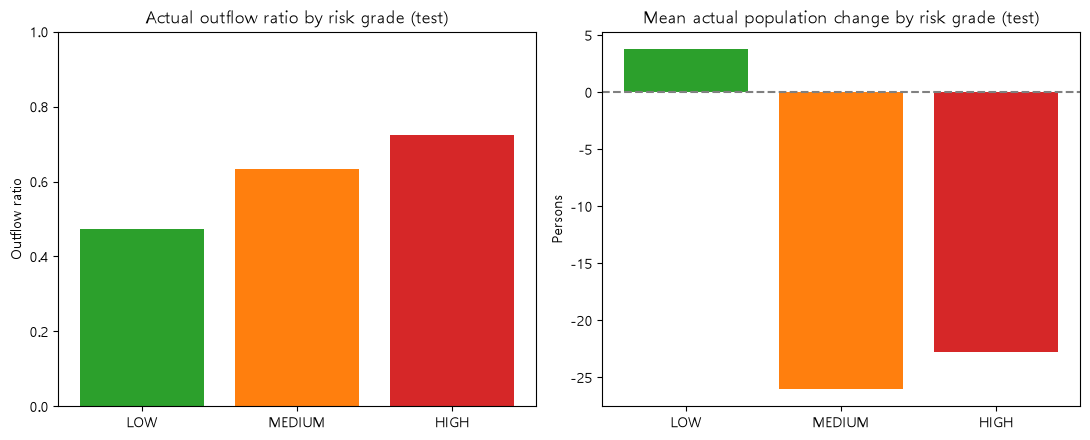

In [9]:
# Plot: actual outflow ratio by grade
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
colors = [GRADE_COLORS[g] for g in summary["risk_grade"]]
axes[0].bar(summary["risk_grade"].astype(str), summary["actual_outflow_ratio"], color=colors)
axes[0].set_ylim(0, 1)
axes[0].set_title("Actual outflow ratio by risk grade (test)")
axes[0].set_ylabel("Outflow ratio")
axes[1].bar(summary["risk_grade"].astype(str), summary["mean_actual_pop_chg"], color=colors)
axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set_title("Mean actual population change by risk grade (test)")
axes[1].set_ylabel("Persons")
plt.tight_layout()
plt.show()

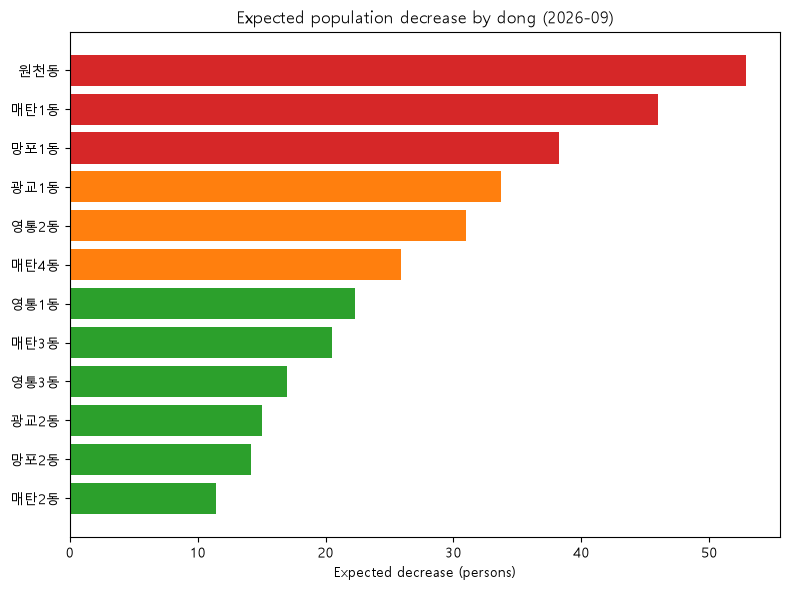

In [10]:
# Plot: latest month expected decrease by dong
plot_df = latest.sort_values("expected_decrease")
plt.figure(figsize=(8, 6))
plt.barh(plot_df["dong"], plot_df["expected_decrease"],
         color=[GRADE_COLORS[g] for g in plot_df["risk_grade"].astype(str)])
plt.title(f"Expected population decrease by dong ({latest_month})")
plt.xlabel("Expected decrease (persons)")
plt.tight_layout()
plt.show()